# OpenCV 09 — Contours & Shape Analysis

Practical APIs for extracting object boundaries and measuring shapes.

## 1. What is a contour?
A contour is a curve joining boundary points of connected foreground regions. It is usually extracted from a binary mask.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = np.zeros((300, 400), dtype=np.uint8)
cv2.rectangle(img, (60, 60), (180, 220), 255, -1)
cv2.circle(img, (290, 150), 70, 255, -1)

contours, hierarchy = cv2.findContours(img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print('Contours:', len(contours))


Contours: 2


## 2. `findContours`
**Syntax:** `cv2.findContours(image, mode, method)`

- `image`: usually a binary, single-channel image
- `mode`: how contours/hierarchy are retrieved
- `method`: how boundary points are stored
- Returns: `(contours, hierarchy)`

### Retrieval modes
- `RETR_EXTERNAL`: outermost contours only.
- `RETR_LIST`: all contours, without parent-child hierarchy.
- `RETR_CCOMP`: two-level hierarchy.
- `RETR_TREE`: full nested hierarchy.

### Approximation methods
- `CHAIN_APPROX_NONE`: stores almost every boundary pixel.
- `CHAIN_APPROX_SIMPLE`: compresses straight segments and usually saves memory.

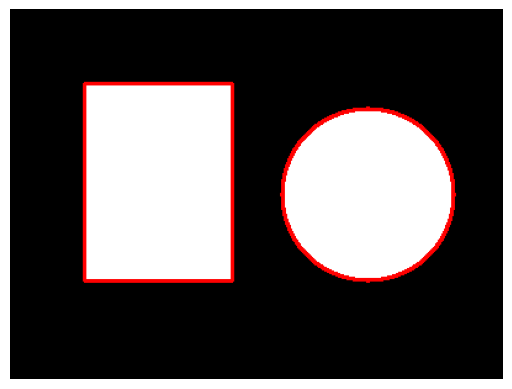

In [ ]:
canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
cv2.drawContours(canvas, contours, -1, (0, 0, 255), 2)
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()


## 3. Contour area
`cv2.contourArea(cnt)` returns the area enclosed by a contour in pixel-coordinate units.

In [4]:
for i, c in enumerate(contours):
    print(i, cv2.contourArea(c))


0 15176.0
1 19200.0


## 4. Arc length / perimeter
`cv2.arcLength(cnt, closed)` computes contour length. Use `closed=True` for a closed object boundary.

In [5]:
for c in contours:
    print('Perimeter:', cv2.arcLength(c, True))


Perimeter: 461.58787727355957
Perimeter: 560.0


## 5. Bounding rectangle
`cv2.boundingRect` gives the smallest axis-aligned rectangle containing the contour: `(x, y, w, h)`.

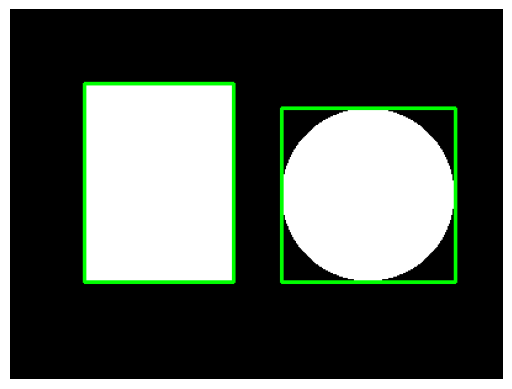

In [ ]:
out = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
for c in contours:
    x, y, w, h = cv2.boundingRect(c)
    cv2.rectangle(out, (x,y), (x+w,y+h), (0,255,0), 2)
plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()


## 6. Minimum enclosing circle
`cv2.minEnclosingCircle(cnt)` finds the smallest circle containing all contour points.

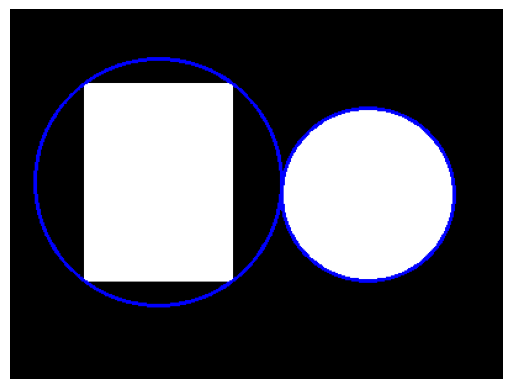

In [ ]:
out = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
for c in contours:
    (cx, cy), r = cv2.minEnclosingCircle(c)
    cv2.circle(out, (int(cx), int(cy)), int(r), (255,0,0), 2)
plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()


## 7. Moments and centroid
For a binary contour, spatial moments summarize its geometry. The centroid is

`cx = M10 / M00`, `cy = M01 / M00`.

`M00` is related to area; always check that it is nonzero before division.

In [8]:
for c in contours:
    M = cv2.moments(c)
    if M['m00'] != 0:
        cx = M['m10'] / M['m00']
        cy = M['m01'] / M['m00']
        print(f'Centroid: ({cx:.1f}, {cy:.1f})')


Centroid: (290.0, 150.0)
Centroid: (120.0, 140.0)


## 8. Image moments — mathematical idea
For a binary region, the raw moment is

`M_pq = Σ x^p y^q I(x,y)`

So `M00 = Σ I`, `M10 = Σ xI`, and `M01 = Σ yI`; their ratios give the intensity-weighted center.

## 9. Contour approximation
`cv2.approxPolyDP(curve, epsilon, closed)` simplifies a contour while keeping its overall shape.

A common choice is `epsilon = 0.02 * perimeter`; larger epsilon gives stronger simplification.

In [9]:
c = max(contours, key=cv2.contourArea)
peri = cv2.arcLength(c, True)
approx = cv2.approxPolyDP(c, 0.02 * peri, True)
print('Original points:', len(c))
print('Approximated points:', len(approx))


Original points: 4
Approximated points: 4


## 10. Shape detection with polygon approximation
A contour with 3, 4, 5, ... approximated vertices can often be classified as triangle, quadrilateral, pentagon, etc. This is a heuristic, not a proof of shape identity.

In [10]:
triangle = np.zeros((300,400), np.uint8)
pts = np.array([[200,40],[80,240],[320,240]], np.int32)
cv2.fillPoly(triangle, [pts], 255)
cs, _ = cv2.findContours(triangle, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
c = cs[0]
approx = cv2.approxPolyDP(c, 0.02*cv2.arcLength(c, True), True)
print('Vertices:', len(approx))


Vertices: 3


## 11. Convex hull
`cv2.convexHull(cnt)` returns the smallest convex polygon enclosing the contour. It fills concavities conceptually like stretching a rubber band around the object.

In [11]:
hull = cv2.convexHull(c)
print('Hull points:', len(hull))


Hull points: 7


## 12. Convexity defects
`cv2.convexityDefects(contour, hull_indices)` identifies deep concave regions relative to the convex hull. It is useful for shapes such as hand/finger silhouettes.

In [12]:
hand = np.zeros((250,300), np.uint8)
pts = np.array([[80,210],[70,100],[95,110],[100,40],[120,100],[135,25],[150,105],[175,45],[170,115],[205,80],[200,145],[225,210]], np.int32)
cv2.fillPoly(hand, [pts], 255)
cs,_=cv2.findContours(hand, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
c=cs[0]
hull_idx=cv2.convexHull(c, returnPoints=False)
if len(hull_idx) >= 4:
    defects=cv2.convexityDefects(c,hull_idx)
    print('Defects:', 0 if defects is None else len(defects))


Defects: 7


## 13. Bounding box vs rotated rectangle
`boundingRect` is axis-aligned. `minAreaRect` finds the smallest-area rotated rectangle, returning center, `(width, height)`, and angle.

In [13]:
box = cv2.minAreaRect(c)
box_pts = cv2.boxPoints(box).astype(np.int32)
print('Center, size, angle:', box)


Center, size, angle: ((144.20492553710938, 120.75410461425781), (144.94773864746094, 192.38845825195312), -5.194428443908691)


## 14. Aspect ratio, extent, solidity
**Aspect ratio:** `w / h` from a bounding rectangle.

**Extent:** `contourArea / (w*h)` — how much of the bounding box is occupied.

**Solidity:** `contourArea / hullArea` — how close the contour is to convex.

In [14]:
area=cv2.contourArea(c)
x,y,w,h=cv2.boundingRect(c)
hull=cv2.convexHull(c)
hull_area=cv2.contourArea(hull)
print('Aspect ratio:', w/h)
print('Extent:', area/(w*h))
print('Solidity:', area/hull_area if hull_area else 0)


Aspect ratio: 0.8387096774193549
Extent: 0.5834194926936862
Solidity: 0.747560167807463


## 15. Circularity
A common roundness measure is

`Circularity = 4πA / P²`

where `A` is area and `P` is perimeter. A perfect circle approaches 1; irregular shapes are lower.

In [15]:
A=cv2.contourArea(c)
P=cv2.arcLength(c, True)
circularity=4*np.pi*A/(P*P) if P else 0
print('Circularity:', circularity)


Circularity: 0.25142746490969653


## 16. Filter contours by area
Area filtering removes tiny blobs caused by noise after thresholding or segmentation.

In [16]:
mask=np.zeros((250,350),np.uint8)
cv2.circle(mask,(90,120),45,255,-1)
cv2.circle(mask,(220,120),8,255,-1)
cs,_=cv2.findContours(mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
kept=[c for c in cs if cv2.contourArea(c)>100]
print('Before:',len(cs),'After:',len(kept))


Before: 2 After: 2


## 17. Complete object-analysis pipeline
**Mask → contours → filter → measure → classify → annotate.** This is one of the most common classical OpenCV shape-analysis workflows.

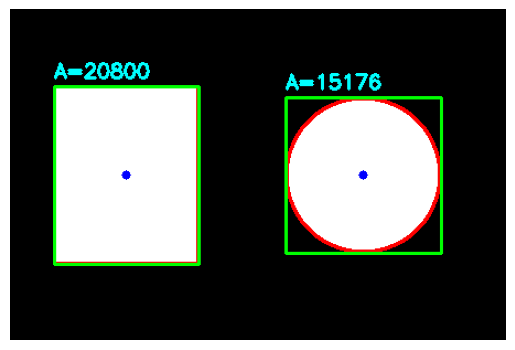

In [17]:
mask=np.zeros((300,450),np.uint8)
cv2.rectangle(mask,(40,70),(170,230),255,-1)
cv2.circle(mask,(320,150),70,255,-1)
cs,_=cv2.findContours(mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
out=cv2.cvtColor(mask,cv2.COLOR_GRAY2BGR)
for i,c in enumerate(cs):
    area=cv2.contourArea(c)
    if area<100: continue
    x,y,w,h=cv2.boundingRect(c)
    M=cv2.moments(c)
    cx=int(M['m10']/M['m00']); cy=int(M['m01']/M['m00'])
    cv2.drawContours(out,[c],-1,(0,0,255),2)
    cv2.rectangle(out,(x,y),(x+w,y+h),(0,255,0),2)
    cv2.putText(out,f'A={area:.0f}',(x,y-8),cv2.FONT_HERSHEY_SIMPLEX,0.6,(255,255,0),2)
    cv2.circle(out,(cx,cy),4,(255,0,0),-1)
plt.imshow(cv2.cvtColor(out,cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()


## 18. Important notes
- `findContours` works best on a clean binary mask.
- Choose retrieval mode based on whether holes/nesting matter.
- Contour coordinates are `(x, y)` = `(column, row)`.
- Area and perimeter are image-coordinate measurements; physical units require camera calibration.
- Shape descriptors are sensitive to segmentation quality.

## 19. Function cheat sheet
| Function | Purpose |
|---|---|
| `findContours` | Extract contours |
| `drawContours` | Draw contours |
| `contourArea` | Area |
| `arcLength` | Perimeter |
| `moments` | Geometric moments |
| `boundingRect` | Axis-aligned box |
| `minAreaRect` | Rotated box |
| `minEnclosingCircle` | Enclosing circle |
| `approxPolyDP` | Polygon approximation |
| `convexHull` | Convex hull |
| `convexityDefects` | Concavity measurements |
